# NHANES 기반 영양소 결핍 다중 레이블 예측 (v2 · 누수 제거 버전)

**v1의 문제점과 v2에서 바뀐 점**
| | v1 | v2 |
|---|---|---|
| 입력 | 라벨을 만든 영양소 수치 자체 | 일반 건강검진 항목 (CBC + 생화학 + 인구통계) |
| 라벨 | 6종 실측 + 3종 난수 | **실측값만** (8종, 마그네슘은 공개 데이터 없음) |
| 비타민D | `LBXVD2MS` (D2 분획) | `LBXVIDMS` (총 25(OH)D, nmol/L) |
| 결측 라벨 | 정상(0)으로 처리 | 마스킹 (학습·평가에서 제외) |
| 임계값 | 테스트셋에서 탐색 | 검증셋에서 결정 |
| 비교 | DNN 단독 | 로지스틱회귀 / Gradient Boosting / DNN + **누수 조건 비교** |
| 반복 | 1회 | 5개 seed 평균±표준편차 |

**실행 방법**: 런타임 > 모두 실행 (T4 GPU 불필요, CPU로 충분). 마지막 셀이 `results.zip`을 내려받습니다.

In [ ]:
# ── 0. 라이브러리 ──
import os, json, warnings, urllib.request, zipfile
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve
from sklearn.inspection import permutation_importance

import tensorflow as tf
from tensorflow import keras

DATA_DIR, OUT_DIR = './nhanes_data', './results'
os.makedirs(DATA_DIR, exist_ok=True); os.makedirs(OUT_DIR, exist_ok=True)
SEEDS = [0, 1, 2, 3, 4]
print('TensorFlow', tf.__version__)

TensorFlow 2.20.0


## 1. 데이터 다운로드 (NHANES 2013-2014 / 2015-2016 / 2017-2018)
사이클마다 측정 항목이 달라서 3개 사이클을 합칩니다. 파일이 없는 사이클은 자동으로 건너뜁니다.
- 아연·B12: 2013-14(아연은 2015-16도)  · 페리틴: 2015-16(가임기 여성), 2017-18(전체)  · 비타민A: 2017-18

In [ ]:
CYCLES = {'H': 2013, 'I': 2015, 'J': 2017}
FILES = ['DEMO', 'BMX', 'CBC', 'BIOPRO',          # 입력(일반 검진)
         'VID', 'FERTIN', 'FOLATE', 'VITB12', 'CUSEZN', 'VITAEC']  # 라벨용

def fetch(name, suffix, year):
    fn = f'{DATA_DIR}/{name}_{suffix}.XPT'
    if os.path.exists(fn):
        return fn
    urls = [f'https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/{year}/DataFiles/{name}_{suffix}.XPT',
            f'https://wwwn.cdc.gov/Nchs/Nhanes/{year}-{year+1}/{name}_{suffix}.XPT']
    for u in urls:
        try:
            req = urllib.request.Request(u, headers={'User-Agent': 'Mozilla/5.0'})
            data = urllib.request.urlopen(req, timeout=60).read()
            if data[:6] == b'HEADER':           # 진짜 XPT 파일인지 확인 (404 HTML 걸러냄)
                open(fn, 'wb').write(data); return fn
        except Exception:
            pass
    return None

avail = {}
for suf, yr in CYCLES.items():
    for name in FILES:
        avail[(name, suf)] = fetch(name, suf, yr) is not None
av = pd.Series(avail).unstack().rename(columns={'H': '2013-14', 'I': '2015-16', 'J': '2017-18'})
print(av.replace({True: 'O', False: '-'}))
av.to_csv(f'{OUT_DIR}/file_availability.csv')

       2013-14 2015-16 2017-18
BIOPRO       O       O       O
BMX          O       O       O
CBC          O       O       O
CUSEZN       O       O       -
DEMO         O       O       O
FERTIN       -       O       O
FOLATE       O       O       O
VID          O       O       O
VITAEC       -       -       O
VITB12       O       -       -


## 2. 병합 · 라벨 생성 (실측값만, 결측은 NaN 유지)

In [ ]:
CBC_COLS = ['LBXWBCSI','LBXLYPCT','LBXMOPCT','LBXNEPCT','LBXEOPCT','LBXBAPCT','LBXRBCSI',
            'LBXHGB','LBXHCT','LBXMCVSI','LBXMCHSI','LBXMC','LBXRDW','LBXPLTSI','LBXMPSI']
# 라벨을 정의하는 수치 (누수 방지를 위해 입력에서 반드시 제외)
MARKERS = ['LBXVIDMS','LBXFER','LBDRFOSI','LBXSCA','LBDB12','LBXSZN','LBXVIA','LBXSIR']

frames = []
for suf in CYCLES:
    if not avail[('DEMO', suf)]:
        continue
    d = pd.read_sas(f'{DATA_DIR}/DEMO_{suf}.XPT')[['SEQN','RIDAGEYR','RIAGENDR','RIDRETH3','INDFMPIR','RIDEXMON']]
    for name in FILES[1:]:
        if avail[(name, suf)]:
            x = pd.read_sas(f'{DATA_DIR}/{name}_{suf}.XPT')
            keep = [c for c in x.columns if c == 'SEQN' or c in MARKERS or c == 'BMXBMI'
                    or c in CBC_COLS or (name == 'BIOPRO' and c.startswith('LBXS'))]
            d = d.merge(x[keep], on='SEQN', how='left')
    d['CYCLE'] = suf
    frames.append(d)
df = pd.concat(frames, ignore_index=True)
for m in MARKERS:
    if m not in df.columns: df[m] = np.nan

# 포함 기준: 20세 이상 + CBC·생화학 검사가 있는 사람
df = df[(df.RIDAGEYR >= 20) & df['LBXHGB'].notna() & df['LBXSAL'].notna()].reset_index(drop=True)

def lab(cond, marker):          # 측정 안 된 사람은 NaN (정상 0으로 두지 않음)
    return np.where(df[marker].isna(), np.nan, cond.astype(float))

male = df.RIAGENDR == 1
LABELS = {
 'VitD (25(OH)D<50 nmol/L)':   lab(df.LBXVIDMS < 50, 'LBXVIDMS'),
 'Iron (ferritin<15 ng/mL)':   lab(df.LBXFER < 15, 'LBXFER'),
 'Folate (RBC<305 nmol/L)':    lab(df.LBDRFOSI < 305, 'LBDRFOSI'),
 'Calcium (<8.5 mg/dL)':       lab(df.LBXSCA < 8.5, 'LBXSCA'),
 'B12 (<200 pg/mL)':           lab(df.LBDB12 < 200, 'LBDB12'),
 'Zinc (<74 M / <70 F ug/dL)': lab(np.where(male, df.LBXSZN < 74, df.LBXSZN < 70), 'LBXSZN'),
 'VitA (retinol<20 ug/dL)':    lab(df.LBXVIA < 20, 'LBXVIA'),
 'Serum iron (<60 ug/dL)':     lab(df.LBXSIR < 60, 'LBXSIR'),
}
SHORT = ['VitD','Iron','Folate','Calcium','B12','Zinc','VitA','S-Iron']
Y = pd.DataFrame(LABELS)
Y.columns = SHORT
keep_lab = [c for c in SHORT if Y[c].notna().sum() > 0]
Y = Y[keep_lab]

cohort = pd.DataFrame({
    'definition': [k for k, s in zip(LABELS, SHORT) if s in keep_lab],
    'n_measured': Y.notna().sum().astype(int),
    'n_deficient': Y.sum().astype(int),
    'prevalence_%': (Y.mean() * 100).round(1),
    'cycles': [','.join(sorted(df.loc[Y[c].notna(), 'CYCLE'].unique())) for c in keep_lab]})
print('대상자 수 (20세 이상, CBC+생화학 보유):', len(df))
print(cohort)
cohort.to_csv(f'{OUT_DIR}/cohort.csv')

대상자 수 (20세 이상, CBC+생화학 보유): 15361
                         definition  n_measured  n_deficient  prevalence_%  \
VitD       VitD (25(OH)D<50 nmol/L)       15359         4692          30.5   
Iron       Iron (ferritin<15 ng/mL)        6271          533           8.5   
Folate      Folate (RBC<305 nmol/L)       13368           31           0.2   
Calcium        Calcium (<8.5 mg/dL)       15329           87           0.6   
B12                B12 (<200 pg/mL)        5312          109           2.1   
Zinc     Zinc (<74 M / <70 F ug/dL)        3462          993          28.7   
VitA        VitA (retinol<20 ug/dL)        4907           18           0.4   
S-Iron       Serum iron (<60 ug/dL)       15337         3844          25.1   

        cycles  
VitD     H,I,J  
Iron       I,J  
Folate   H,I,J  
Calcium  H,I,J  
B12          H  
Zinc       H,I  
VitA         J  
S-Iron   H,I,J  


## 3. 입력 피처 정의
- **Leak-free (본 연구)**: CBC 15항목 + 생화학 패널(칼슘·철 제외) + 나이·성별·인종·소득비·BMI·검진 계절
- **Leaky (v1 재현)**: 위 + 라벨을 정의한 영양소 수치 8개 → 누수가 성능을 얼마나 부풀리는지 비교용

모든 사이클에 공통으로 있는 컬럼만 사용 (사이클별 결측 패턴이 정답 힌트가 되는 것 방지)

In [ ]:
bio = [c for c in df.columns if c.startswith('LBXS') and c not in MARKERS]
base = CBC_COLS + bio + ['RIDAGEYR','RIAGENDR','INDFMPIR','BMXBMI','RIDEXMON']
# 사이클 공통 컬럼만 (어떤 사이클에서 90% 이상 결측이면 제외)
base = [c for c in base if c in df.columns and df.groupby('CYCLE')[c].apply(lambda s: s.notna().mean()).min() > 0.1]
X_free = df[base].copy()
X_free = pd.concat([X_free, pd.get_dummies(df.RIDRETH3, prefix='race', dtype=float)], axis=1)
X_leak = pd.concat([X_free, df[MARKERS]], axis=1)
FEATS_FREE, FEATS_LEAK = list(X_free.columns), list(X_leak.columns)
print(f'Leak-free 피처 {len(FEATS_FREE)}개:', FEATS_FREE)

Leak-free 피처 48개: ['LBXWBCSI', 'LBXLYPCT', 'LBXMOPCT', 'LBXNEPCT', 'LBXEOPCT', 'LBXBAPCT', 'LBXRBCSI', 'LBXHGB', 'LBXHCT', 'LBXMCVSI', 'LBXMCHSI', 'LBXMC', 'LBXRDW', 'LBXPLTSI', 'LBXMPSI', 'LBXSAL', 'LBXSAPSI', 'LBXSASSI', 'LBXSATSI', 'LBXSBU', 'LBXSC3SI', 'LBXSCH', 'LBXSCK', 'LBXSCLSI', 'LBXSCR', 'LBXSGB', 'LBXSGL', 'LBXSGTSI', 'LBXSKSI', 'LBXSLDSI', 'LBXSNASI', 'LBXSOSSI', 'LBXSPH', 'LBXSTB', 'LBXSTP', 'LBXSTR', 'LBXSUA', 'RIDAGEYR', 'RIAGENDR', 'INDFMPIR', 'BMXBMI', 'RIDEXMON', 'race_1.0', 'race_2.0', 'race_3.0', 'race_4.0', 'race_6.0', 'race_7.0']


## 4. 모델 정의 (로지스틱회귀 · Gradient Boosting · 다중 레이블 DNN)

In [ ]:
def masked_bce(pos_w):
    pos_w = tf.constant(pos_w, tf.float32)
    def loss(y_true, y_pred):
        mask = tf.cast(~tf.math.is_nan(y_true), tf.float32)        # 측정된 라벨만 손실 계산
        y = tf.where(tf.math.is_nan(y_true), tf.zeros_like(y_true), y_true)
        p = tf.clip_by_value(y_pred, 1e-7, 1 - 1e-7)
        l = -(pos_w * y * tf.math.log(p) + (1 - y) * tf.math.log(1 - p))
        return tf.reduce_sum(l * mask) / tf.maximum(tf.reduce_sum(mask), 1.0)
    return loss

def build_dnn(d_in, d_out, pos_w, seed):
    tf.keras.utils.set_random_seed(seed)
    m = keras.Sequential([
        keras.layers.Input((d_in,)),
        keras.layers.Dense(128, activation='relu'), keras.layers.BatchNormalization(), keras.layers.Dropout(0.4),
        keras.layers.Dense(64, activation='relu'),  keras.layers.BatchNormalization(), keras.layers.Dropout(0.3),
        keras.layers.Dense(32, activation='relu'),  keras.layers.Dropout(0.2),
        keras.layers.Dense(d_out, activation='sigmoid')])
    m.compile(optimizer=keras.optimizers.Adam(1e-3), loss=masked_bce(pos_w))
    return m

def per_label_model(kind, seed):
    if kind == 'LR':
        return make_pipeline(SimpleImputer(strategy='median'), StandardScaler(),
                             LogisticRegression(max_iter=2000, class_weight='balanced'))
    return HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, early_stopping=True,
                                          class_weight='balanced', random_state=seed)

def youden_thr(y, p):
    fpr, tpr, thr = roc_curve(y, p)
    return thr[np.argmax(tpr - fpr)]

def evaluate(y_te, p_te, y_va, p_va):
    m = ~np.isnan(y_te); mv = ~np.isnan(y_va)
    yt, pt = y_te[m], p_te[m]
    if yt.sum() < 2 or (1 - yt).sum() < 2:
        return dict(auroc=np.nan, auprc=np.nan, sens=np.nan, spec=np.nan, n_pos=int(yt.sum()))
    t = youden_thr(y_va[mv], p_va[mv]) if 0 < y_va[mv].sum() < mv.sum() else 0.5   # 임계값은 검증셋에서
    pred = pt >= t
    return dict(auroc=roc_auc_score(yt, pt), auprc=average_precision_score(yt, pt),
                sens=(pred & (yt == 1)).sum() / yt.sum(), spec=(~pred & (yt == 0)).sum() / (1 - yt).sum(),
                n_pos=int(yt.sum()))

## 5. 실험 (5개 seed × 3개 모델 × 2개 입력 조건)

In [ ]:
rows, last = [], {}
Yv = Y.values
for seed in SEEDS:
    idx = np.arange(len(df))
    tr, tmp = train_test_split(idx, test_size=0.30, random_state=seed)
    va, te = train_test_split(tmp, test_size=0.50, random_state=seed)

    for setting, X in [('leak-free', X_free), ('leaky', X_leak)]:
        Xv = X.values.astype(float)
        # ── 로지스틱회귀 / Gradient Boosting: 라벨별로, 측정된 사람만 학습 ──
        for kind in ['LR', 'GBM']:
            for j, lab_name in enumerate(Y.columns):
                mtr = ~np.isnan(Yv[tr, j])
                if Yv[tr, j][mtr].sum() < 5:
                    continue
                cols = ~np.all(np.isnan(Xv[tr][mtr]), axis=0)          # 이 라벨 대상자에게 전부 결측인 컬럼 제외
                clf = per_label_model(kind, seed).fit(Xv[tr][mtr][:, cols], Yv[tr, j][mtr])
                p_te, p_va = clf.predict_proba(Xv[te][:, cols])[:, 1], clf.predict_proba(Xv[va][:, cols])[:, 1]
                rows.append(dict(seed=seed, setting=setting, model=kind, label=lab_name,
                                 **evaluate(Yv[te, j], p_te, Yv[va, j], p_va)))
                if seed == SEEDS[0] and setting == 'leak-free' and kind == 'GBM':
                    last[lab_name] = (clf, te, cols)
        # ── DNN: 하나의 모델이 모든 라벨을 동시에 예측 (결측 라벨은 마스킹) ──
        imp, sc = SimpleImputer(strategy='median').fit(Xv[tr]), StandardScaler()
        Xtr = sc.fit_transform(imp.transform(Xv[tr])); Xva = sc.transform(imp.transform(Xv[va])); Xte = sc.transform(imp.transform(Xv[te]))
        prev = np.nanmean(Yv[tr], axis=0)
        pos_w = np.clip(np.sqrt((1 - prev) / np.maximum(prev, 1e-3)), 1, 20)     # 희귀 결핍에 가중치
        dnn = build_dnn(Xtr.shape[1], Yv.shape[1], pos_w, seed)
        dnn.fit(Xtr, Yv[tr], validation_data=(Xva, Yv[va]), epochs=200, batch_size=256, verbose=0,
                callbacks=[keras.callbacks.EarlyStopping(patience=15, restore_best_weights=True),
                           keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=7)])
        P_te, P_va = dnn.predict(Xte, verbose=0), dnn.predict(Xva, verbose=0)
        for j, lab_name in enumerate(Y.columns):
            rows.append(dict(seed=seed, setting=setting, model='DNN', label=lab_name,
                             **evaluate(Yv[te, j], P_te[:, j], Yv[va, j], P_va[:, j])))
    print(f'seed {seed} 완료')

res = pd.DataFrame(rows)
res.to_csv(f'{OUT_DIR}/results_raw.csv', index=False)

seed 0 완료
seed 1 완료
seed 2 완료
seed 3 완료
seed 4 완료


## 6. 결과 표 (평균 ± 표준편차)

In [ ]:
def ms(s): return f'{s.mean():.3f}±{s.std():.3f}' if s.notna().any() else 'n/a'
order = list(Y.columns)
tab = (res.groupby(['setting', 'model', 'label'])
          .agg(AUROC=('auroc', ms), AUPRC=('auprc', ms), Sens=('sens', ms), Spec=('spec', ms),
               test_pos=('n_pos', 'mean')).reset_index())
tab['label'] = pd.Categorical(tab['label'], order); tab = tab.sort_values(['setting', 'model', 'label'])
tab.to_csv(f'{OUT_DIR}/results_table.csv', index=False)

# 논문 표 2용: 라벨 × 모델 AUROC (leak-free) + leaky DNN
wide = res.groupby(['setting', 'model', 'label']).auroc.mean().unstack('label')[order].round(3)
macro = res.groupby(['setting', 'model', 'seed']).auroc.mean().groupby(['setting', 'model']).agg(['mean', 'std']).round(3)
pd.set_option('display.width', 200)
print('=== 라벨별 AUROC (5-seed 평균) ===');  print(wide)
print('\n=== Macro AUROC (라벨 평균) ===');    print(macro)
print('\n=== Leak-free DNN 상세 ===')
print(tab[(tab.setting == 'leak-free') & (tab.model == 'DNN')].to_string(index=False))
wide.to_csv(f'{OUT_DIR}/auroc_wide.csv'); macro.to_csv(f'{OUT_DIR}/auroc_macro.csv')

=== 라벨별 AUROC (5-seed 평균) ===
label             VitD   Iron  Folate  Calcium    B12   Zinc   VitA  S-Iron
setting   model                                                            
leak-free DNN    0.767  0.941   0.755    0.916  0.598  0.670  0.925   0.801
          GBM    0.764  0.940   0.552    0.784  0.618  0.706  0.861   0.811
          LR     0.764  0.946   0.676    0.861  0.668  0.720  0.830   0.808
leaky     DNN    0.999  0.965   0.945    0.994  0.948  0.997  0.960   0.999
          GBM    1.000  1.000   0.999    1.000  1.000  1.000  0.999   1.000
          LR     1.000  0.989   0.996    0.999  0.992  0.999  0.966   1.000

=== Macro AUROC (라벨 평균) ===
                  mean    std
setting   model              
leak-free DNN    0.798  0.013
          GBM    0.760  0.021
          LR     0.788  0.025
leaky     DNN    0.976  0.011
          GBM    1.000  0.000
          LR     0.993  0.003

=== Leak-free DNN 상세 ===
  setting model   label       AUROC       AUPRC        Sens        

## 7. 그림 (논문용, 300dpi)

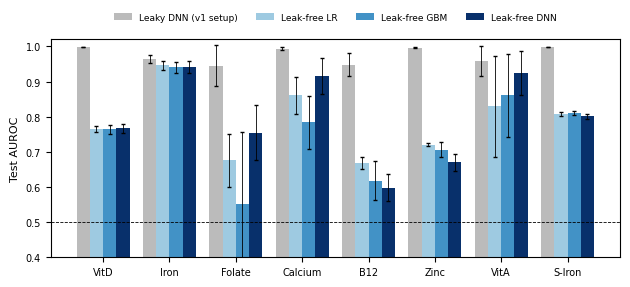

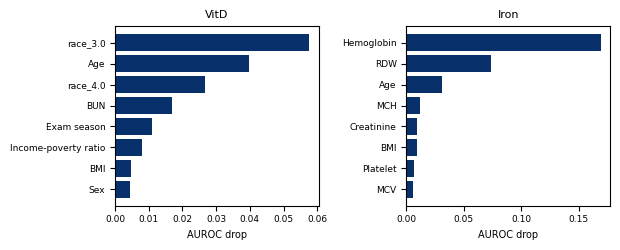

In [ ]:
# 그림 1: 누수 유무에 따른 라벨별 AUROC
g = res.groupby(['setting', 'model', 'label']).auroc.agg(['mean', 'std'])
series = [('leaky', 'DNN', 'Leaky DNN (v1 setup)', '#bbbbbb'),
          ('leak-free', 'LR', 'Leak-free LR', '#9ecae1'),
          ('leak-free', 'GBM', 'Leak-free GBM', '#4292c6'),
          ('leak-free', 'DNN', 'Leak-free DNN', '#08306b')]
fig, ax = plt.subplots(figsize=(6.4, 3.0))
w = 0.2; x = np.arange(len(order))
for k, (s, m, name, col) in enumerate(series):
    mu = [g.loc[(s, m, l), 'mean'] if (s, m, l) in g.index else np.nan for l in order]
    sd = [g.loc[(s, m, l), 'std'] if (s, m, l) in g.index else np.nan for l in order]
    ax.bar(x + (k - 1.5) * w, mu, w, yerr=sd, label=name, color=col, capsize=1.5, error_kw={'lw': 0.6})
ax.axhline(0.5, color='k', lw=0.6, ls='--')
ax.set_xticks(x); ax.set_xticklabels(order, fontsize=8); ax.set_ylim(0.4, 1.02)
ax.set_ylabel('Test AUROC', fontsize=8); ax.tick_params(labelsize=7)
ax.legend(fontsize=6.5, ncol=4, loc='upper center', bbox_to_anchor=(0.5, 1.16), frameon=False)
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/fig1_auroc.png', dpi=300, bbox_inches='tight'); plt.show()

# 그림 2: 주요 라벨의 중요 피처 (GBM, permutation importance, seed 0)
show = [l for l in ['VitD', 'Iron', 'B12', 'S-Iron'] if l in last][:2]
fig, axes = plt.subplots(1, len(show), figsize=(3.2 * len(show), 2.6))
axes = np.atleast_1d(axes)
for ax, l in zip(axes, show):
    clf, te_idx, cols = last[l]; j = order.index(l); m = ~np.isnan(Yv[te_idx, j])
    pi = permutation_importance(clf, X_free.values[te_idx][m][:, cols], Yv[te_idx, j][m], scoring='roc_auc',
                                n_repeats=5, random_state=0)
    NM = {'LBXHGB':'Hemoglobin','LBXHCT':'Hematocrit','LBXMCVSI':'MCV','LBXMCHSI':'MCH','LBXMC':'MCHC','LBXRDW':'RDW',
          'LBXRBCSI':'RBC','LBXWBCSI':'WBC','LBXPLTSI':'Platelet','LBXMPSI':'MPV','LBXSAL':'Albumin','LBXSAPSI':'ALP',
          'LBXSATSI':'ALT','LBXSASSI':'AST','LBXSGTSI':'GGT','LBXSCH':'Cholesterol','LBXSTR':'Triglyceride','LBXSGL':'Glucose',
          'LBXSCR':'Creatinine','LBXSBU':'BUN','LBXSUA':'Uric acid','LBXSTP':'Total protein','LBXSGB':'Globulin','LBXSPH':'Phosphorus',
          'LBXSCK':'CPK','LBXSLDSI':'LDH','LBXSTB':'Bilirubin','LBXSOSSI':'Osmolality','LBXSNASI':'Sodium','LBXSKSI':'Potassium',
          'LBXSCLSI':'Chloride','LBXSC3SI':'Bicarbonate','LBXLYPCT':'Lymphocyte %','LBXMOPCT':'Monocyte %','LBXNEPCT':'Neutrophil %',
          'LBXEOPCT':'Eosinophil %','LBXBAPCT':'Basophil %','RIDAGEYR':'Age','RIAGENDR':'Sex','INDFMPIR':'Income-poverty ratio',
          'BMXBMI':'BMI','RIDEXMON':'Exam season'}
    s = pd.Series(pi.importances_mean, [NM.get(c, c) for c in np.array(FEATS_FREE)[cols]]).sort_values().tail(8)
    ax.barh(s.index, s.values, color='#08306b'); ax.set_title(l, fontsize=8)
    ax.tick_params(labelsize=6.5); ax.set_xlabel('AUROC drop', fontsize=7)
    s.to_csv(f'{OUT_DIR}/importance_{l}.csv')
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/fig2_importance.png', dpi=300, bbox_inches='tight'); plt.show()

## 8. 결과

In [ ]:
with open(f'{OUT_DIR}/summary.txt', 'w') as f:
    f.write(f'N (adults, CBC+BIOPRO) = {len(df)}\n')
    f.write(f'cycles = {df.CYCLE.value_counts().to_dict()}\n')
    f.write(f'n_features leak-free = {len(FEATS_FREE)}\n{FEATS_FREE}\n\n')
    f.write(cohort.to_string() + '\n\n' + wide.to_string() + '\n\n' + macro.to_string() + '\n\n' + tab.to_string(index=False))
with zipfile.ZipFile('results.zip', 'w') as z:
    for fn in os.listdir(OUT_DIR): z.write(f'{OUT_DIR}/{fn}', fn)
print(open(f'{OUT_DIR}/summary.txt').read()[:3000])
try:
    from google.colab import files; files.download('results.zip')
except ImportError:
    print('results.zip 저장 완료')

N (adults, CBC+BIOPRO) = 15361
cycles = {'H': 5324, 'I': 5123, 'J': 4914}
n_features leak-free = 48
['LBXWBCSI', 'LBXLYPCT', 'LBXMOPCT', 'LBXNEPCT', 'LBXEOPCT', 'LBXBAPCT', 'LBXRBCSI', 'LBXHGB', 'LBXHCT', 'LBXMCVSI', 'LBXMCHSI', 'LBXMC', 'LBXRDW', 'LBXPLTSI', 'LBXMPSI', 'LBXSAL', 'LBXSAPSI', 'LBXSASSI', 'LBXSATSI', 'LBXSBU', 'LBXSC3SI', 'LBXSCH', 'LBXSCK', 'LBXSCLSI', 'LBXSCR', 'LBXSGB', 'LBXSGL', 'LBXSGTSI', 'LBXSKSI', 'LBXSLDSI', 'LBXSNASI', 'LBXSOSSI', 'LBXSPH', 'LBXSTB', 'LBXSTP', 'LBXSTR', 'LBXSUA', 'RIDAGEYR', 'RIAGENDR', 'INDFMPIR', 'BMXBMI', 'RIDEXMON', 'race_1.0', 'race_2.0', 'race_3.0', 'race_4.0', 'race_6.0', 'race_7.0']

                         definition  n_measured  n_deficient  prevalence_% cycles
VitD       VitD (25(OH)D<50 nmol/L)       15359         4692          30.5  H,I,J
Iron       Iron (ferritin<15 ng/mL)        6271          533           8.5    I,J
Folate      Folate (RBC<305 nmol/L)       13368           31           0.2  H,I,J
Calcium        Calcium (<8.5 mg

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>